# Lesson 5, Lab B: tracking people across frames

**Complete notebook.** Every cell runs as it is. This lab is a
demonstration, and the code in it is the starting point for the teams whose
CA1 twist needs identity, T4 and T5.

## What this lab is

The baseline reads direction from one photograph and has no idea that the person
in this frame is the person from the last one. Anything measured over time needs
that link: how long somebody waited, how fast they crossed, whether one person
was counted once or five times.

Keeping that link is called tracking. This lab runs a production tracker,
ByteTrack, which ships inside Ultralytics, over a short video from a fixed
camera, looks at what it produces, and then pushes its settings until it breaks.

## The order of work

1. Setup and the model from Lesson 3
2. The clip
3. A detector has no memory
4. Running the tracker
5. Looking at it, which is how tracking is actually debugged
6. Counting people rather than detections
7. Where the tracker breaks
8. From tracks to the twists: what T4 and T5 build next

## Timing

Roughly 40 minutes as a demonstration. Section 5 is the one not to skip, and
Section 8 is the one T4 and T5 teams should read twice.

---

## 1. Setup

Ultralytics is the same pinned version as Lessons 3 and 4, since weights and
library have to agree. `lap` is the small library the tracker uses to solve the
matching between boxes.

In [1]:
ULTRALYTICS_VERSION = "8.4.120"

try:
    import google.colab  # noqa: F401
    RUNNING_ON_COLAB = True
except ImportError:
    RUNNING_ON_COLAB = False

if RUNNING_ON_COLAB:
    import subprocess
    # Ultralytics installs lap itself the first time a tracker runs, which works
    # but prints a page of noise in the middle of the demo. Installed here instead.
    subprocess.run(
        ["pip", "install", "-q", "ultralytics==" + ULTRALYTICS_VERSION, "lap"],
        check=True,
    )

print("Running on Colab:", RUNNING_ON_COLAB)

Running on Colab: True


In [3]:
import json
import os
import time
from collections import Counter

import cv2
from PIL import Image, ImageDraw
from ultralytics import YOLO

if RUNNING_ON_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = "/content/drive/MyDrive/C389"
else:
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))

WEIGHTS = os.path.join(PROJECT_ROOT, "artifacts", "L3", "best.pt")
WORK_DIR = os.path.join(PROJECT_ROOT, "artifacts", "Ca1")
os.makedirs(WORK_DIR, exist_ok=True)

print("weights :", WEIGHTS)
print("output  :", WORK_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
weights : /content/drive/MyDrive/C389/artifacts/L3/best.pt
output  : /content/drive/MyDrive/C389/artifacts/Ca1


### Which weights

The tracker can only follow what the detector finds, so the weights have to
match the clip:

- **A real clip of the walkway** uses `best.pt` from Lesson 3, trained on the
  class's own photographs
- **The drawn sample clip** uses weights trained on the drawn sample set, which
  ship beside the clip. A model trained on photographs finds nobody in a drawing,
  and every number in this notebook would then be zero
- **A real clip with no Lesson 3 weights** falls back to the stock model, which
  tracks people well enough and reports every one of them as `person`, with no
  direction

In [5]:
# A team's own clip goes on Drive here. Without one, the drawn sample clip is used.
TEAM_CLIP = os.path.join(PROJECT_ROOT, "data", "clips", "fastnslow.mp4")
SAMPLE_WEIGHTS = os.path.join(PROJECT_ROOT, "data", "sample", "clip",
                              "sample_walkway.pt")

if not os.path.exists(TEAM_CLIP):
    MODEL_PATH = "yolo26n.pt"
    print("WARNING: a team clip but no best.pt at %s" % WEIGHTS)
    print("Falling back to the stock model. It tracks people and cannot report")
    print("direction. Run Lesson 3 to the end for the real weights.")
    MODEL_PATH = SAMPLE_WEIGHTS
print("")

MODEL = YOLO(MODEL_PATH)
CLASS_NAMES = [MODEL.names[key] for key in sorted(MODEL.names)]

# Only people are tracked. A twist that appended a class to the model, such as a
# suitcase, still has its people tracked here and nothing else.
PERSON_CLASS_IDS = [index for index, name in enumerate(CLASS_NAMES)
                    if name.startswith("person")]

print("model   :", MODEL_PATH)
print("classes :", CLASS_NAMES)
print("tracked :", [CLASS_NAMES[index] for index in PERSON_CLASS_IDS])


model   : yolo26n.pt
classes : ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush']
tracked : ['person']


---

## 2. The clip

Tracking needs video, or at least frames taken at a steady interval, from a
camera that does not move. Photographs taken whenever somebody walked past are
not enough, however many there are.

### Recording a clip that can be tracked

This is the capture protocol for any team whose twist needs identity. None of it
can be fixed afterwards.

- **The phone does not move.** On a tripod, a clamp or a wall, never in a hand.
  Every pixel position in Sections 6 to 8 means a place on the ground only while
  the camera stays exactly where it was
- **Landscape, side on or at about 45 degrees,** with the whole width of the
  walkway in view, and people large enough to detect at the far side
- **30 to 60 seconds per clip,** at the phone's normal video setting. Longer
  than the longest thing being measured: a wait, or a slow crossing
- **Write down where the phone stood,** and photograph the setup, so that the
  next session can put it back in the same place
- **T5 only:** two marks on the ground, along the direction people walk, with the
  distance between them measured **with a tape, on the day**
- **T4 only:** decide where the waiting area is before recording, and make sure
  something visible in the frame marks its edges

Upload the clip to Drive as `data/clips/walkway.mp4` under the project folder.
Without one, the notebook uses a drawn sample clip.

clip     : /content/drive/MyDrive/C389/data/clips/fastnslow.mp4
frames   : 366 at 30.02 per second, 12.2 seconds
size     : 1280 x 720


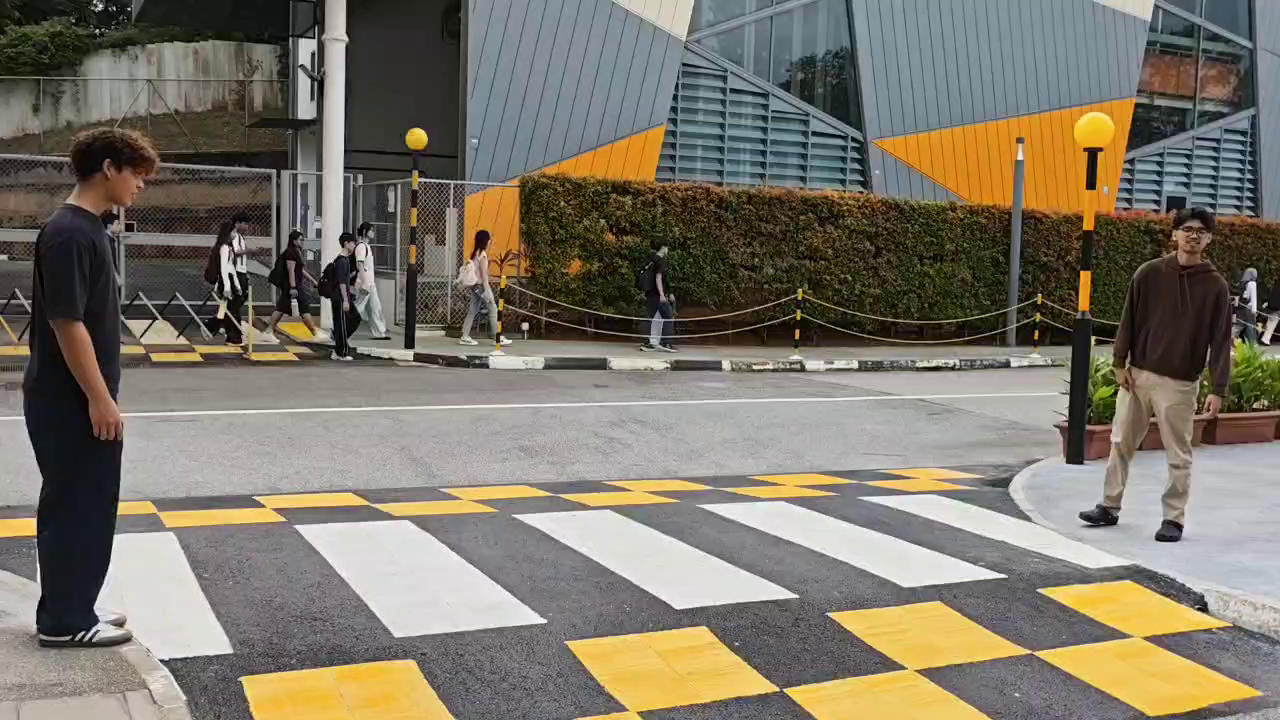

In [6]:
SAMPLE_CLIP_DIR = os.path.join(PROJECT_ROOT, "data", "sample", "clip")

if os.path.exists(TEAM_CLIP):
    CLIP_PATH = TEAM_CLIP
    CLIP_TRUTH = None
    USING_SAMPLE_CLIP = False
else:
    truth_path = os.path.join(SAMPLE_CLIP_DIR, "clip.json")
    if not os.path.exists(truth_path):
        raise FileNotFoundError(
            "No team clip at %s and no sample clip at %s.\n"
            "Upload a clip, or run scripts/make_sample_data.py."
            % (TEAM_CLIP, SAMPLE_CLIP_DIR))
    with open(truth_path, encoding="utf-8") as handle:
        CLIP_TRUTH = json.load(handle)
    CLIP_PATH = os.path.join(SAMPLE_CLIP_DIR, CLIP_TRUTH["file"])
    USING_SAMPLE_CLIP = True


def read_frame(path, index):
    """One frame of a video, as OpenCV returns it: a BGR array."""
    video = cv2.VideoCapture(path)
    video.set(cv2.CAP_PROP_POS_FRAMES, index)
    ok, frame = video.read()
    video.release()
    if not ok:
        raise ValueError("Could not read frame %d of %s" % (index, path))
    return frame


def as_picture(frame):
    """An OpenCV frame as a PIL image, which is what a notebook displays."""
    return Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))


video = cv2.VideoCapture(CLIP_PATH)
if not video.isOpened():
    raise ValueError("OpenCV cannot open %s" % CLIP_PATH)
CLIP = {
    "fps": video.get(cv2.CAP_PROP_FPS),
    "frames": int(video.get(cv2.CAP_PROP_FRAME_COUNT)),
    "width": int(video.get(cv2.CAP_PROP_FRAME_WIDTH)),
    "height": int(video.get(cv2.CAP_PROP_FRAME_HEIGHT)),
}
video.release()

print("clip     :", CLIP_PATH)
print("frames   : %d at %.2f per second, %.1f seconds"
      % (CLIP["frames"], CLIP["fps"], CLIP["frames"] / CLIP["fps"]))
print("size     : %d x %d" % (CLIP["width"], CLIP["height"]))
if USING_SAMPLE_CLIP:
    print("")
    print("WARNING: the drawn sample clip. It proves the code runs. Its people,")
    print("speeds and events were placed on purpose, and nothing measured on it says")
    print("anything about a real walkway.")

FIRST_FRAME = as_picture(read_frame(CLIP_PATH, 0))
FIRST_FRAME

---

## 3. A detector has no memory

Run the Lesson 3 model on two frames one second apart. Each frame gets a list of
boxes, and that is all. Nothing in the second list says which box is the same
person as a box in the first.

In [7]:
LOOK_AT = CLIP["frames"] // 2
ONE_SECOND = int(round(CLIP["fps"]))
FOUND = 0

for index in (LOOK_AT, LOOK_AT + ONE_SECOND):
    result = MODEL.predict(read_frame(CLIP_PATH, index), conf=0.25,
                           classes=PERSON_CLASS_IDS, verbose=False)[0]
    print("frame %d, at %.1f s" % (index, index / CLIP["fps"]))
    for box, class_id, confidence in zip(result.boxes.xyxy.tolist(),
                                          result.boxes.cls.int().tolist(),
                                          result.boxes.conf.tolist()):
        print("   %-13s %.2f   feet at x = %4.0f"
              % (CLASS_NAMES[class_id], confidence, (box[0] + box[2]) / 2))
    if len(result.boxes) == 0:
        print("   nothing detected")
    FOUND = FOUND + len(result.boxes)
    print("")

if not FOUND:
    print("The model found nobody in either frame, so everything below will be")
    print("zero. Check that the weights printed in Section 1 match the clip.")

frame 183, at 6.1 s
   person        0.90   feet at x =  686
   person        0.90   feet at x =  467
   person        0.59   feet at x =  304
   person        0.59   feet at x = 1001
   person        0.58   feet at x =  218
   person        0.55   feet at x =  602
   person        0.52   feet at x =  925
   person        0.42   feet at x =  795
   person        0.33   feet at x =  835
   person        0.25   feet at x = 1075

frame 213, at 7.1 s
   person        0.91   feet at x =  635
   person        0.91   feet at x =  472
   person        0.64   feet at x =  997
   person        0.56   feet at x =  404
   person        0.50   feet at x =  470
   person        0.42   feet at x =  807
   person        0.39   feet at x =  906
   person        0.38   feet at x =  334
   person        0.32   feet at x =  859



A person can be matched by eye: similar height in the frame, a little further
along. A tracker does exactly that, many times a second, and gives each person a
number that stays with them.

---

## 4. Running the tracker

`model.track` runs the detector on a frame and then hands the boxes to a
tracker. ByteTrack, the default used here, does three things on every frame:

1. **Predicts** where each person it already knows about should be now, from how
   they were moving
2. **Matches** the new boxes to those predictions by how much they overlap. A
   box that matches keeps that person's number. A confident box that matches
   nobody starts a new number
3. **Remembers** a person who was not matched for a while, in case they come
   back from behind something, and forgets them only after that

`persist=True` is what makes it tracking. It tells Ultralytics to keep the
tracker's memory between calls, so frame 2 is matched against what was seen in
frame 1.

The clip is read one frame at a time rather than handed over whole. That keeps
memory flat on a long clip, and it gives every observation its frame number and
therefore its time, which is the whole point for T4 and T5.

In [8]:
TRACKER = "bytetrack.yaml"
CONFIDENCE = 0.25


def track_clip(path, tracker=TRACKER, frame_step=1, confidence=CONFIDENCE,
               save_video_to=None):
    """Run the tracker over a clip and collect what it reports for every identity.

    Args:
        path: the video file
        tracker: a tracker settings file, bytetrack.yaml or one written in Section 7
        frame_step: 1 tracks every frame, 3 tracks every third frame, and so on
        confidence: detections below this are never seen by the tracker
        save_video_to: optional path for a copy of the clip with the tracks drawn on

    Returns:
        dict of track id to a list of observations in time order. Each observation
        holds the frame number, the time in seconds, the box, the point between the
        feet, the class the model gave the box, and its confidence
    """
    # A fresh model for every run. The tracker lives inside the model object, so
    # reusing one with persist=True would carry the last run's identities, and the
    # last run's settings, into this one.
    model = YOLO(MODEL_PATH)

    video = cv2.VideoCapture(path)
    fps = video.get(cv2.CAP_PROP_FPS)
    writer = None
    tracks = {}
    index = -1

    while True:
        ok, frame = video.read()
        if not ok:
            break
        index = index + 1
        if index % frame_step:
            continue

        result = model.track(frame, persist=True, tracker=tracker,
                             conf=confidence, classes=PERSON_CLASS_IDS,
                             verbose=False)[0]

        # A box with no id is one the tracker has not accepted as a person yet,
        # typically the first frame somebody appears. It is left out.
        if result.boxes is not None and result.boxes.id is not None:
            for box, track_id, class_id, score in zip(
                    result.boxes.xyxy.tolist(), result.boxes.id.int().tolist(),
                    result.boxes.cls.int().tolist(), result.boxes.conf.tolist()):
                left, top, right, bottom = box
                tracks.setdefault(track_id, []).append({
                    "frame": index,
                    "seconds": round(index / fps, 3),
                    "box": [round(value, 1) for value in box],
                    # The feet, not the centre of the box. The feet are on the
                    # ground, where waiting areas and measured marks are.
                    "foot": [round((left + right) / 2, 1), round(bottom, 1)],
                    "class_name": CLASS_NAMES[class_id],
                    "confidence": round(score, 3),
                })

        if save_video_to:
            if writer is None:
                height, width = frame.shape[:2]
                writer = cv2.VideoWriter(save_video_to,
                                         cv2.VideoWriter_fourcc(*"mp4v"),
                                         fps / frame_step, (width, height))
            writer.write(result.plot())

    video.release()
    if writer is not None:
        writer.release()
    return tracks

In [9]:
TRACKED_VIDEO = os.path.join(WORK_DIR, "tracked.mp4")

started = time.time()
TRACKS = track_clip(CLIP_PATH, save_video_to=TRACKED_VIDEO)
taken = time.time() - started

print("tracked %d frames in %.1f s, %.0f frames per second"
      % (CLIP["frames"], taken, CLIP["frames"] / taken))
print("identities produced :", len(TRACKS))
if USING_SAMPLE_CLIP:
    print("people in the clip  :", len(CLIP_TRUTH["people_present"]))

if not TRACKS:
    print("")
    print("Nothing was tracked. The tracker only follows what the detector finds, so")
    print("this is a detection problem. Check that the weights printed in Section 1")
    print("match the clip. On a real clip, check that people are large enough in the")
    print("frame and try a lower CONFIDENCE.")

tracked 366 frames in 13.2 s, 28 frames per second
identities produced : 110


The video below is the clip with every tracked box drawn on and its number above
it. Watch one person from the moment they enter to the moment they leave, and
see whether their number ever changes.

In [10]:
import base64
import shutil
import subprocess

from IPython.display import HTML


def show_video(path, width=640):
    """Play a video inside the notebook.

    OpenCV writes a codec that browsers will not play, so the file is converted
    first. Colab has ffmpeg. Elsewhere, open the file itself.
    """
    if not shutil.which("ffmpeg"):
        print("No ffmpeg here. Open %s instead." % path)
        return None
    playable = path.replace(".mp4", "_playable.mp4")
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", path,
                    "-vf", "scale=%d:-2" % width, "-vcodec", "libx264",
                    "-pix_fmt", "yuv420p", playable], check=True)
    with open(playable, "rb") as handle:
        data = base64.b64encode(handle.read()).decode("ascii")
    return HTML('<video width="%d" controls><source src="data:video/mp4;base64,%s" '
                'type="video/mp4"></video>' % (width, data))


show_video(TRACKED_VIDEO)

Output hidden; open in https://colab.research.google.com to view.

---

## 5. Look at it

Every identity drawn as a path along the ground, on the first frame of the clip.
Do not skip this and read the numbers instead.

Debugging tracking numerically is slow and miserable. Debugging it by looking at
the paths takes a few seconds:

- **A colour that changes part way along one continuous path** is one person who
  became two. The tracker lost them and started again
- **Two paths that swap colour where they cross** are two people who exchanged
  numbers

   id frames   from s     to s class          feet moved, px
    1    272      0.0      9.3 person                  -1116 
    2    365      0.0     12.2 person                  +1138 
    3    267      0.0     10.9 person                   +747 
    4     66      0.0      2.2 person                   +292 
    5    136      0.0      4.6 person                   +331 
    6    108      0.0      4.3 person                   +339 
    7      3      0.0      0.1 person                     +0 flicker
    8      3      0.0      0.1 person                     +4 flicker
    9      1      0.0      0.0 person                     +0 flicker
   10      1      0.0      0.0 person                     +0 flicker
   11    120      0.0      8.6 person                   +681 
   16      1      0.2      0.2 person                     +0 flicker
   24      4      0.3      0.4 person                     +7 flicker
   30      2      0.5      0.5 person                     +1 flicker
   40    101      0.6 

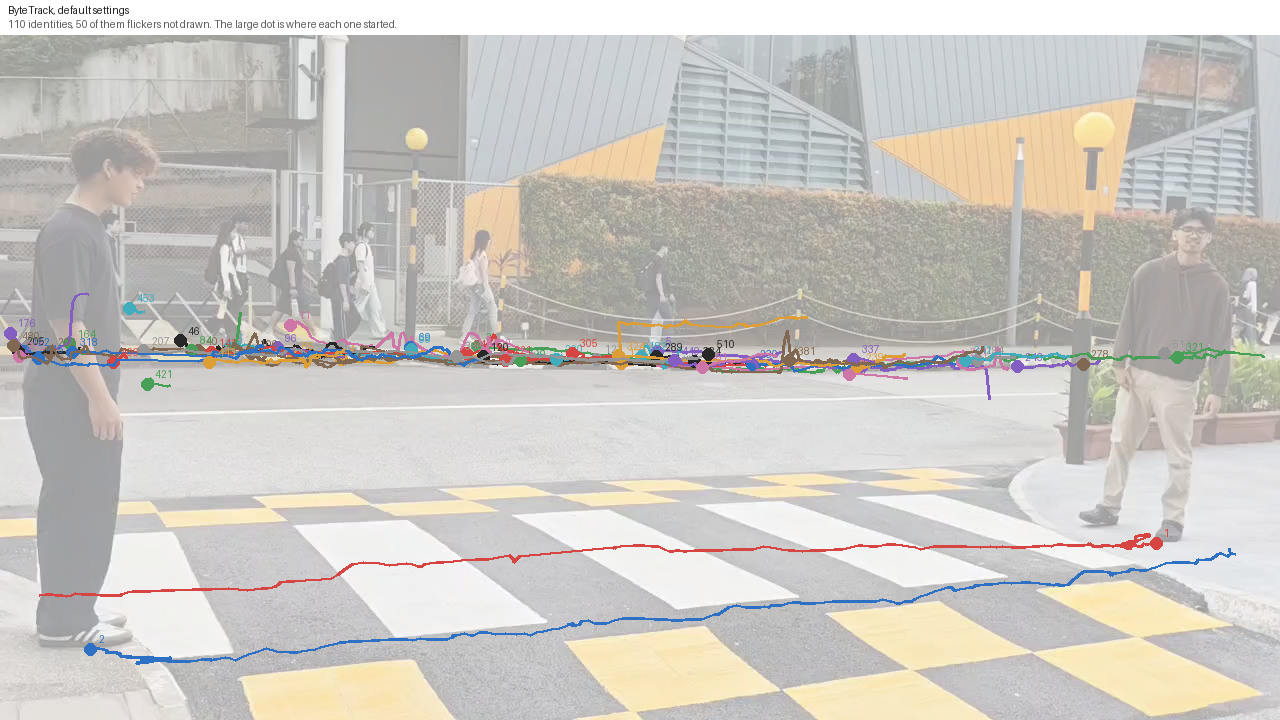

In [11]:
TRACK_COLOURS = [
    (214, 69, 65), (46, 112, 196), (72, 160, 88), (222, 158, 54),
    (132, 94, 194), (64, 172, 190), (206, 118, 168), (128, 104, 82),
    (40, 40, 40), (150, 150, 150),
]


# An identity seen in fewer frames than this is a flicker: a number the tracker
# started for a doubtful box and never saw again, usually a second, weaker box on
# somebody who already has one. Flickers are listed in the table and left out of
# the picture, where they would only add dots.
FLICKER_BELOW = 5


def track_colours(tracks):
    """One colour per lasting identity, in the order they appeared.

    Tracker numbers jump, 2 then 12 then 40, so colouring by number would give
    two different people the same colour often enough to mislead.
    """
    lasting = [t for t in sorted(tracks) if len(tracks[t]) >= FLICKER_BELOW]
    return {track_id: TRACK_COLOURS[index % len(TRACK_COLOURS)]
            for index, track_id in enumerate(lasting)}


def draw_tracks(background, tracks, title):
    """Every track as a coloured path through the feet, on one picture."""
    # Faded, so the paths are what stands out.
    canvas = Image.blend(background, Image.new("RGB", background.size, "white"), 0.6)
    draw = ImageDraw.Draw(canvas)
    colours = track_colours(tracks)
    lasting = sorted(colours)
    for track_id in lasting:
        colour = colours[track_id]
        points = [tuple(observation["foot"]) for observation in tracks[track_id]]
        if len(points) > 1:
            draw.line(points, fill=colour, width=3)
        x, y = points[0]
        draw.ellipse([x - 6, y - 6, x + 6, y + 6], fill=colour)
        draw.text((x + 8, y - 16), str(track_id), fill=colour)
    draw.rectangle([0, 0, canvas.width, 34], fill=(255, 255, 255))
    draw.text((8, 4), title, fill=(30, 30, 30))
    draw.text((8, 18), "%d identities, %d of them flickers not drawn. The large dot "
              "is where each one started." % (len(tracks), len(tracks) - len(lasting)),
              fill=(90, 90, 90))
    return canvas


def majority_class(observations):
    """The class the model gave this person most often."""
    return Counter(o["class_name"] for o in observations).most_common(1)[0][0]


def describe_tracks(tracks):
    print("%5s %6s %8s %8s %-13s %15s"
          % ("id", "frames", "from s", "to s", "class", "feet moved, px"))
    for track_id in sorted(tracks):
        observations = tracks[track_id]
        moved = observations[-1]["foot"][0] - observations[0]["foot"][0]
        print("%5d %6d %8.1f %8.1f %-13s %+15.0f %s"
              % (track_id, len(observations), observations[0]["seconds"],
                 observations[-1]["seconds"], majority_class(observations), moved,
                 "flicker" if len(observations) < FLICKER_BELOW else ""))


describe_tracks(TRACKS)
draw_tracks(FIRST_FRAME, TRACKS, "ByteTrack, default settings")

### Checking against the truth, on the sample clip only

The drawn clip comes with a record of where every figure was drawn in every
frame, so on it each identity can be checked rather than only counted. Two
failures are counted separately because they have different causes:

- **fragment:** one real person given more than one identity
- **swap:** one identity that covered more than one real person

A real clip has no such record. On a real clip, the picture above is the check.

The flickers in the table are not counted as fragments. A flicker is a second,
weaker box on somebody who already has an identity, which the tracker numbered
and then never saw again. They inflate the number of identities without being a
person, which is one more reason the number of identities is not a count.

In [12]:
def overlap(first, second):
    """Intersection over union of two boxes."""
    width = min(first[2], second[2]) - max(first[0], second[0])
    height = min(first[3], second[3]) - max(first[1], second[1])
    if width <= 0 or height <= 0:
        return 0.0
    shared = width * height
    area = ((first[2] - first[0]) * (first[3] - first[1])
            + (second[2] - second[0]) * (second[3] - second[1]) - shared)
    return shared / area


def score_tracks(tracks, truth, quiet=False):
    """Fragments, swaps and missed people, measured against the clip's truth boxes.

    An observation is credited to whichever drawn figure its box overlaps most.
    A person or an identity counts only with three or more observations behind
    it, so a single doubtful frame where two figures overlap is not a swap.
    """
    drawn = {}
    for name, rows in truth["truth_boxes"].items():
        for frame, *box in rows:
            drawn.setdefault(frame, []).append((name, box))

    person_to_ids = {}
    id_to_people = {}
    for track_id, observations in tracks.items():
        for observation in observations:
            best, name = 0.3, None
            for candidate, box in drawn.get(observation["frame"], []):
                score = overlap(observation["box"], box)
                if score > best:
                    best, name = score, candidate
            if name is None:
                continue
            person_to_ids.setdefault(name, Counter())[track_id] += 1
            id_to_people.setdefault(track_id, Counter())[name] += 1

    fragments = {name: sorted(i for i, n in ids.items() if n >= 3)
                 for name, ids in person_to_ids.items()}
    fragments = {name: ids for name, ids in fragments.items() if len(ids) > 1}
    swaps = {track_id: sorted(p for p, n in people.items() if n >= 3)
             for track_id, people in id_to_people.items()}
    swaps = {track_id: people for track_id, people in swaps.items() if len(people) > 1}
    missed = [name for name in truth["people_present"]
              if not any(n >= 3 for n in person_to_ids.get(name, {}).values())]

    if not quiet:
        print("identities produced : %d for %d people"
              % (len(tracks), len(truth["people_present"])))
        for name in missed:
            print("  missed  : %s was never tracked" % name)
        for name in sorted(fragments):
            print("  fragment: %s was given identities %s" % (name, fragments[name]))
        for track_id in sorted(swaps):
            print("  swap    : identity %d covered %s"
                  % (track_id, " and ".join(swaps[track_id])))
        if not fragments and not swaps and not missed:
            print("  every person has one identity and every identity one person")
    return fragments, swaps, missed


if USING_SAMPLE_CLIP:
    score_tracks(TRACKS, CLIP_TRUTH)
else:
    print("A real clip has no truth record. Read the picture in Section 5.")

A real clip has no truth record. Read the picture in Section 5.


---

## 6. Counting people rather than detections

The project rule from Lesson 3 is that a count is per image: one person
photographed ten times is ten detections and one person. A single photograph
cannot do better than that. A tracked clip can.

Draw a line across the walkway and count each identity once, when its feet cross
it. Direction is still the class the model was trained to give, taken as the
class it gave that person most often. The movement across the line only decides
that somebody crossed, and when.

In [13]:
# Where the line goes is a decision about the site. Somewhere everybody passes,
# away from anything that hides people.
COUNT_LINE_X = int(CLIP["width"] * 0.4)


def crossings(tracks, line_x):
    """Every time an identity's feet pass from one side of a vertical line to the other.

    Returns a list of (track id, frame, movement), in time order. Movement is
    "left to right" or "right to left" across the frame.
    """
    events = []
    for track_id, observations in tracks.items():
        for before, after in zip(observations, observations[1:]):
            was = before["foot"][0] - line_x
            now = after["foot"][0] - line_x
            if was < 0 <= now:
                events.append((track_id, after["frame"], "left to right"))
            elif was >= 0 > now:
                events.append((track_id, after["frame"], "right to left"))
    return sorted(events, key=lambda event: event[1])


EVENTS = crossings(TRACKS, COUNT_LINE_X)
CROSSED = sorted({track_id for track_id, _, _ in EVENTS})

counted = Counter(majority_class(TRACKS[track_id]) for track_id in CROSSED)
detections = sum(len(observations) for observations in TRACKS.values())
busiest = Counter(o["frame"] for obs in TRACKS.values() for o in obs).most_common(1)

print("line at x = %d" % COUNT_LINE_X)
print("")
print("detections summed over every frame : %d" % detections)
print("most people in any one frame       : %d" % (busiest[0][1] if busiest else 0))
print("identities that crossed the line   : %d" % len(CROSSED))
for name in sorted(counted):
    print("   %-13s %d" % (name, counted[name]))

line at x = 512

detections summed over every frame : 3394
most people in any one frame       : 15
identities that crossed the line   : 15
   person        15


Compare the three numbers. Summing detections over every frame counts each
person once per frame they were seen. The most in any one frame is the best a
single photograph can do. The crossing count is people.

The crossing count can be right even when the number of identities is wrong,
because a split that happens away from the line does not change who crossed it.
A split or a swap **at** the line does: it can count somebody twice, or hand
their crossing to someone else. So the line goes somewhere people are seen
clearly, away from posts, doorways and anywhere people bunch together.

In [14]:
# The trained class and the movement should agree. Where they do not, either the
# model read the direction wrong or the tracker joined two people. Both are worth
# a look in the video before anything is reported.
print("%5s %7s %-15s %-13s %s" % ("id", "frame", "movement", "class", ""))
for track_id, frame, movement in EVENTS:
    name = majority_class(TRACKS[track_id])
    agrees = (name == "person_right") == (movement == "left to right")
    flag = "" if name not in ("person_left", "person_right") or agrees else "DISAGREES"
    print("%5d %7d %-15s %-13s %s" % (track_id, frame, movement, name, flag))

   id   frame movement        class         
    3      10 left to right   person        
    4      34 left to right   person        
   64      43 left to right   person        
   11      66 left to right   person        
  102      74 left to right   person        
  120      81 left to right   person        
    6     101 left to right   person        
   40     113 left to right   person        
  106     139 left to right   person        
  221     147 left to right   person        
    2     190 left to right   person        
    1     210 right to left   person        
  207     246 left to right   person        
  202     255 left to right   person        
  386     274 left to right   person        


---

## 7. Where the tracker breaks

Three settings decide almost everything, and the useful thing is finding where
each one fails on this clip rather than knowing that it can.

| Setting | What it is | Too low | Too high |
|---|---|---|---|
| `track_buffer` | how many frames a lost person is remembered | somebody who walks behind a post comes out as a new person | somebody who left is still remembered, and can be handed to a newcomer |
| `match_thresh` | how much mismatch a match may have. The default 0.8 accepts a box that overlaps where the person was expected by roughly a fifth | matches are refused and people fragment | the wrong box is accepted and identities swap |
| frame step | how many frames are skipped between the ones tracked | slow, and more storage | people move further between frames than a match can follow |

`track_buffer` is counted in **frames the tracker sees**, not in seconds. 30
frames is one second of a 30 frame per second phone video, three seconds of the
sample clip, and nine seconds of the sample clip tracked at a frame step of 3.
A setting copied from somebody else's clip means something different on yours.

The settings live in a small file. The cell below copies the default ByteTrack
file with one or two values changed.

In [15]:
import yaml
from ultralytics.utils import ROOT as ULTRALYTICS_ROOT

DEFAULT_SETTINGS_FILE = os.path.join(str(ULTRALYTICS_ROOT), "cfg", "trackers",
                                     "bytetrack.yaml")
with open(DEFAULT_SETTINGS_FILE, encoding="utf-8") as handle:
    DEFAULT_SETTINGS = yaml.safe_load(handle)


def tracker_settings(name, **changes):
    """Write a copy of the ByteTrack settings with some values changed."""
    unknown = set(changes) - set(DEFAULT_SETTINGS)
    if unknown:
        raise KeyError("ByteTrack has no setting called %s" % ", ".join(sorted(unknown)))
    settings = dict(DEFAULT_SETTINGS)
    settings.update(changes)
    path = os.path.join(WORK_DIR, name + ".yaml")
    with open(path, "w", encoding="utf-8") as handle:
        yaml.safe_dump(settings, handle)
    return path


for key in sorted(DEFAULT_SETTINGS):
    print("%-18s %s" % (key, DEFAULT_SETTINGS[key]))

fuse_score         True
match_thresh       0.8
new_track_thresh   0.25
track_buffer       30
track_high_thresh  0.25
track_low_thresh   0.1
tracker_type       bytetrack


In [16]:
def report(label, tracks):
    """One row of a sweep: identities, and on the sample clip what went wrong."""
    if USING_SAMPLE_CLIP:
        fragments, swaps, missed = score_tracks(tracks, CLIP_TRUTH, quiet=True)
        notes = ["%s never tracked" % name for name in missed]
        notes += ["%s split into %d" % (name, len(ids)) for name, ids in sorted(fragments.items())]
        notes += ["one identity covers %s" % " and ".join(people) for people in swaps.values()]
        note = ", ".join(notes) or "clean"
    else:
        note = "look at the picture"
    print("%-22s %10d   %s" % (label, len(tracks), note))


print("%-22s %10s   %s" % ("track_buffer", "identities", "what happened"))
for buffer in (1, 5, 30, 90):
    settings = tracker_settings("buffer_%d" % buffer, track_buffer=buffer)
    report(str(buffer), track_clip(CLIP_PATH, tracker=settings))

track_buffer           identities   what happened
1                             173   look at the picture
5                             142   look at the picture
30                            110   look at the picture
90                            101   look at the picture


Read down the table rather than only at the bottom.

At 1 frame almost everybody is split, because any single frame where the
detector wavers ends an identity. As the buffer grows, the splits stop, and the
last one to stop is whoever spends longest hidden: on the drawn clip, the slow
walker behind the lamp post.

Then keep reading. A longer memory is not automatically a safer one. An identity
kept alive after somebody has gone is still there to be matched, and somewhere
in the larger values a new problem can appear that the smaller ones did not have.
Write down both: the smallest buffer that stopped the splits, and the first one,
if any, that caused new trouble.

In [17]:
print("%-22s %10s   %s" % ("frame step", "identities", "what happened"))
for step in (1, 2, 4, 8):
    label = "%d, %.1f frames a second" % (step, CLIP["fps"] / step)
    report(label, track_clip(CLIP_PATH, frame_step=step))

frame step             identities   what happened
1, 30.0 frames a second        110   look at the picture
2, 15.0 frames a second         60   look at the picture
4, 7.5 frames a second         38   look at the picture
8, 3.8 frames a second         33   look at the picture


Skipping frames is the same as recording at a lower frame rate. Between the
frames that are tracked people move further, a person's box in one frame barely
overlaps their box in the next, and the tracker can no longer link them.

The fastest walkers go first, and notice how: they are not split, they are
**never tracked at all**. A new identity is only confirmed once it has been
matched in a second frame, and somebody who has moved too far by then never gets
one. A count built on these tracks would not be slightly low. It would be missing
whole people, silently.

This is the frame rate requirement in the capture protocol seen from the other
side. A phone recording at 30 frames a second is plenty. A timelapse, or a photo
every few seconds, is not.

In [18]:
print("%-22s %10s   %s" % ("match_thresh", "identities", "what happened"))
for threshold in (0.3, 0.6, 0.8, 0.95):
    settings = tracker_settings("match_%d" % int(threshold * 100), match_thresh=threshold)
    report(str(threshold), track_clip(CLIP_PATH, tracker=settings))

match_thresh           identities   what happened
0.3                          1003   look at the picture
0.6                           393   look at the picture
0.8                           110   look at the picture
0.95                           73   look at the picture


At the strict end almost nothing is allowed to match, so the tracker starts new
numbers for people over and over and the identity count explodes.

At the loose end boxes are accepted that belong to somebody else, and one
identity ends up covering more than one person. That is the worse failure,
because the number of identities does not reveal it: it can even come out lower
and look like an improvement. Only the picture in Section 5, or a truth record,
shows it.

The default sits between the two for a reason. Leave it there unless the picture
shows a specific problem that a change fixes, and record what the change cost.

---

## 8. From tracks to the twists

Everything above produces one thing: for each person, a list of times and the
point between their feet at each time. That list is the raw material for both
twists that need identity. Plotting the feet against time shows what each twist
is looking for.

/tmp/ipykernel_545/635504900.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


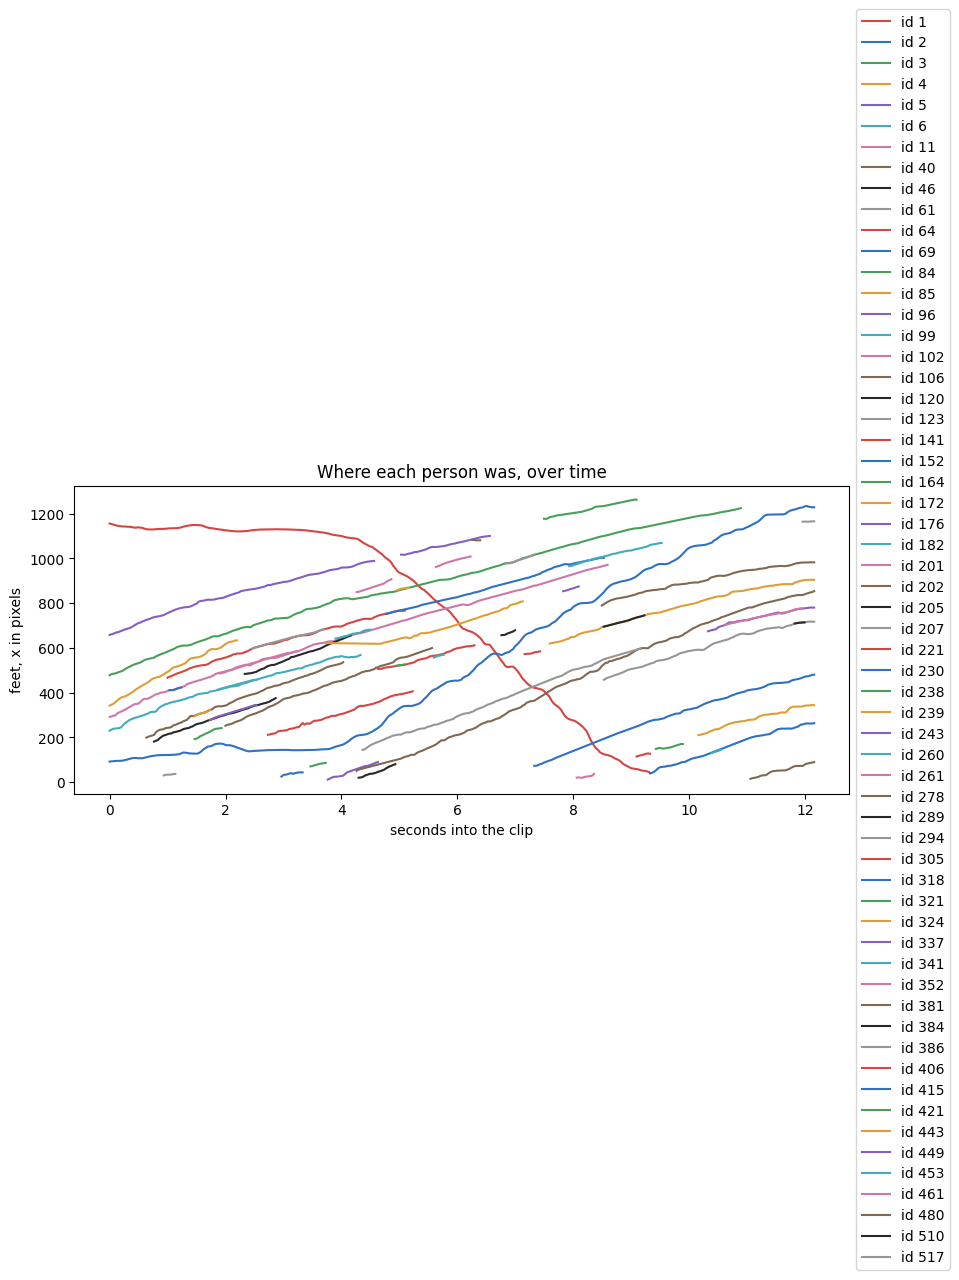

In [19]:
import matplotlib.pyplot as plt

figure, axes = plt.subplots(figsize=(10, 4))
for track_id, colour in track_colours(TRACKS).items():
    observations = TRACKS[track_id]
    axes.plot([o["seconds"] for o in observations],
              [o["foot"][0] for o in observations],
              color=[c / 255 for c in colour], label="id %d" % track_id)
axes.set_xlabel("seconds into the clip")
axes.set_ylabel("feet, x in pixels")
axes.set_title("Where each person was, over time")
if axes.get_legend_handles_labels()[0]:
    axes.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.show()

**A flat stretch is somebody standing still. That is T4.** A sloped stretch is
somebody walking, and the steepness is their speed in pixels per second. **That
is T5.**

The tracks are saved below, so twist work can start from them without running
the detector again.

In [20]:
TRACKS_FILE = os.path.join(WORK_DIR, "tracks.json")

with open(TRACKS_FILE, "w", encoding="utf-8") as handle:
    json.dump({
        "clip": CLIP_PATH,
        "fps": CLIP["fps"],
        "frame_width": CLIP["width"],
        "frame_height": CLIP["height"],
        "tracker": TRACKER,
        "tracks": {str(track_id): observations
                   for track_id, observations in TRACKS.items()},
    }, handle, indent=1)

print("saved %d identities to %s" % (len(TRACKS), TRACKS_FILE))

# Reading them back, in a twist notebook:
with open(TRACKS_FILE, encoding="utf-8") as handle:
    saved = json.load(handle)
tracks = {int(track_id): rows for track_id, rows in saved["tracks"].items()}
print("read back %d identities" % len(tracks))

saved 110 identities to /content/drive/MyDrive/C389/artifacts/Ca1/tracks.json
read back 110 identities


### T4: waiting against crossing

What is built next, by the team:

1. **The waiting area,** as a rectangle in pixels of this camera position, drawn
   on the first frame to check it lands where it should
2. **A rule for "standing still",** from the feet moving less than some number of
   pixels per second, over a window long enough that one slow step does not count
3. **A rule for "waiting",** from standing still inside the area for at least
   some number of seconds
4. **How long each person waited,** from the time stamps

Decisions the team owns and has to justify: the area, both thresholds and the
window. Things that will go wrong:

- A person who fragments while standing is two short waits, not one long one.
  Check the picture in Section 5 before trusting a dwell time
- Somebody already waiting when the clip starts, or still waiting when it ends,
  waited longer than the clip shows. Every such time is **at least** that long,
  and the report has to say so
- Pixel positions only mean the waiting area while the camera has not moved

### T5: speed and clearance time

What is built next, by the team:

1. **The two marks,** as two x positions in pixels, read off the first frame,
   and the distance between them in metres from the tape
2. **The moment each person's feet cross each mark,** using the same idea as
   `crossings` in Section 6
3. **Speed,** as metres between the marks over seconds between the crossings.
   This needs no conversion from pixels to metres at all, which is the reason to
   measure two marks rather than one length somewhere in the frame
4. **The clearance time** for the walkway at the **slowest** walking speed, not
   the average

Decisions the team owns and have to justify: where the marks go, who counts as
walking rather than standing, and what to do with somebody who crosses only one
mark. Things that will go wrong:

- Somebody who walks at an angle covers more ground than the distance between the
  marks, so their speed comes out low. Side on footage keeps this small
- Feet, not the centre of the box. The box centre moves when somebody swings an
  arm or carries something
- A fragment between the two marks loses that person entirely. A larger
  `track_buffer` helps, up to the point Section 7 showed it stops helping
- Time comes from frame numbers and the frame rate. Check the frame rate this
  notebook printed against the phone's setting

### Before leaving

- The tracked video was watched, and the path picture in Section 5 was looked at,
  not only the number of identities
- The three settings in Section 7 were swept, with the value where each one broke
  written down from this run
- Teams on T4 or T5 have a capture plan that covers the protocol in Section 2:
  a phone that does not move, a clip longer than what is being measured, and for
  T5 two marks measured with a tape on the day

None of that is recoverable after the capture session has finished.

---

## T5: Speed and clearance

Built on the tracks from Sections 4 to 8. Nothing above this line is changed.

What this section does:

1. Two marks on the ground (x positions in pixels) and the tape-measured distance between them
2. The moment each person's feet cross each mark, **interpolated between frames**
3. Speed = metres between the marks / seconds between the two crossings. No pixel to metre conversion is needed
4. People slower than a threshold are flagged
5. Clearance time = full walkway width / the **slowest** walking speed, not the average

Fill in the four numbers in the next cell from your capture session. The values there are
placeholders so the notebook runs.

In [23]:
# ---- T5 settings. Everything the team has to decide or measure is here. ----

# Marks as x positions in pixels, read off the first frame (the picture below
MARK_A_X = int(CLIP["width"] * 0.10)
MARK_B_X = int(CLIP["width"] * 0.80)

# MEASURED WITH A TAPE. Metres between the two marks on the ground.
MARK_DISTANCE_M = 4.8

# Full width to be crossed, in metres, along the direction people walk.
WALKWAY_WIDTH_M = 4.8

# A walker slower than this is flagged (m/s). Justify the value in the report.
# 1.0 m/s is a common slow-walker design speed, but it is the team's decision.
SLOW_THRESHOLD_MS = 0.8

if USING_SAMPLE_CLIP:
    print("WARNING: sample clip. The distances above are placeholders, so every")
    print("speed below only proves the code runs.")
print("marks at x = %d and x = %d, %.2f m apart" % (MARK_A_X, MARK_B_X, MARK_DISTANCE_M))
print("frame rate used for time: %.2f fps (check against the phone's setting)" % CLIP["fps"])

marks at x = 128 and x = 1024, 4.80 m apart
frame rate used for time: 30.02 fps (check against the phone's setting)


### Check the marks on the first frame

Do this before trusting any speed. If the lines are not on the ground marks, change
`MARK_A_X` and `MARK_B_X`. Speed only means anything if the pixel marks sit on
the real marks.

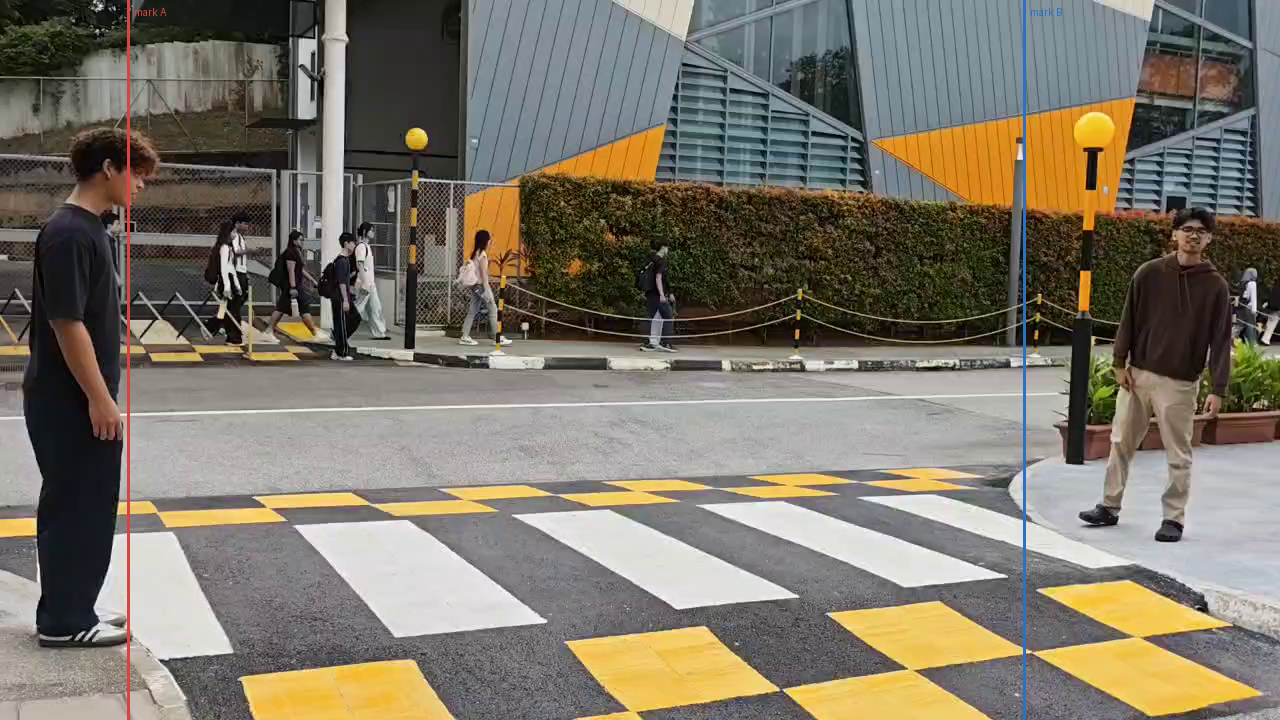

In [24]:
def draw_marks(background, mark_a, mark_b):
    canvas = background.copy()
    draw = ImageDraw.Draw(canvas)
    for label, x, colour in (("A", mark_a, (214, 69, 65)), ("B", mark_b, (46, 112, 196))):
        draw.line([(x, 0), (x, canvas.height)], fill=colour, width=3)
        draw.text((x + 6, 6), "mark " + label, fill=colour)
    return canvas

draw_marks(FIRST_FRAME, MARK_A_X, MARK_B_X)

---

### Crossing times and speeds

`mark_crossing` finds the first time a person's feet go from one side of a mark to the
other. The time is interpolated between the two frames either side of the mark, so
it is not rounded to the nearest frame. At 30 frames per second that rounding would be
up to 0.03 s per crossing, which matters over a short distance.

A person is left out of the speed table, and listed with the reason, if:

- they are a flicker (seen in fewer than `FLICKER_BELOW` frames)
- they crossed only one mark. This is usually a fragmented track
- they crossed the two marks in opposite directions (turned back between them)

In [25]:
def mark_crossing(observations, mark_x):
    """First time the feet pass a vertical mark, as (seconds, direction), or None.

    The time is worked out between the two frames either side of the mark.
    """
    for before, after in zip(observations, observations[1:]):
        x0, x1 = before["foot"][0], after["foot"][0]
        went_right = x0 < mark_x <= x1
        went_left = x0 >= mark_x > x1
        if not (went_right or went_left):
            continue
        fraction = (mark_x - x0) / (x1 - x0)
        seconds = before["seconds"] + fraction * (after["seconds"] - before["seconds"])
        return seconds, ("left to right" if went_right else "right to left")
    return None


def walking_speeds(tracks, mark_a, mark_b, distance_m):
    """Speed of every identity that crossed both marks, plus who was left out and why.

    Returns (rows, left_out). Each row is a dict with the track id, class,
    direction, crossing times, seconds between them, speed in m/s and a status:
    standing, slow or ok. left_out maps a track id to the reason.
    """
    rows, left_out = [], {}
    for track_id in sorted(tracks):
        observations = tracks[track_id]
        if len(observations) < FLICKER_BELOW:
            left_out[track_id] = "flicker (%d frames)" % len(observations)
            continue

        first = mark_crossing(observations, mark_a)
        second = mark_crossing(observations, mark_b)
        if first is None and second is None:
            continue  # never reached the marks, nothing to report
        if first is None or second is None:
            left_out[track_id] = "crossed only mark %s" % ("A" if second is None else "B")
            continue
        if first[1] != second[1]:
            left_out[track_id] = "crossed the marks in opposite directions"
            continue

        elapsed = abs(second[0] - first[0])
        if elapsed <= 0:
            left_out[track_id] = "no time between the crossings"
            continue

        speed = distance_m / elapsed
        if speed < SLOW_THRESHOLD_MS:
            status = "slow"
        else:
            status = "ok"
        rows.append({
            "track_id": track_id,
            "class_name": majority_class(observations),
            "direction": first[1],
            "seconds_at_a": round(first[0], 3),
            "seconds_at_b": round(second[0], 3),
            "seconds_between": round(elapsed, 3),
            "speed_ms": round(speed, 3),
            "status": status,
        })
    return rows, left_out


SPEEDS, LEFT_OUT = walking_speeds(TRACKS, MARK_A_X, MARK_B_X, MARK_DISTANCE_M)

print("%5s %-13s %-14s %8s %8s %9s %9s  %s"
      % ("id", "class", "direction", "at A, s", "at B, s", "between s", "speed m/s", "status"))
for row in SPEEDS:
    print("%5d %-13s %-14s %8.2f %8.2f %9.2f %9.2f  %s"
          % (row["track_id"], row["class_name"], row["direction"], row["seconds_at_a"],
             row["seconds_at_b"], row["seconds_between"], row["speed_ms"],
             row["status"].upper() if row["status"] != "ok" else ""))

if LEFT_OUT:
    print("")
    print("left out of the table:")
    for track_id, reason in sorted(LEFT_OUT.items()):
        print("   id %-4d %s" % (track_id, reason))
if not SPEEDS:
    print("")
    print("Nobody crossed both marks. Check the marks in the picture above, and the")
    print("tracks in Section 5.")

   id class         direction       at A, s  at B, s between s speed m/s  status
    1 person        right to left      8.49     4.67      3.82      1.26  
    2 person        left to right      1.24     9.90      8.67      0.55  SLOW

left out of the table:
   id 3    crossed only mark B
   id 7    flicker (3 frames)
   id 8    flicker (3 frames)
   id 9    flicker (1 frames)
   id 10   flicker (1 frames)
   id 16   flicker (1 frames)
   id 24   flicker (4 frames)
   id 30   flicker (2 frames)
   id 42   flicker (3 frames)
   id 65   flicker (1 frames)
   id 86   flicker (3 frames)
   id 108  flicker (4 frames)
   id 109  flicker (2 frames)
   id 115  flicker (2 frames)
   id 144  flicker (3 frames)
   id 151  flicker (3 frames)
   id 167  flicker (4 frames)
   id 169  flicker (2 frames)
   id 202  crossed only mark A
   id 203  flicker (3 frames)
   id 212  flicker (3 frames)
   id 215  flicker (3 frames)
   id 225  flicker (2 frames)
   id 243  crossed only mark B
   id 246  flicker

### Slowest walker and clearance time

The clearance time uses the **slowest** speed among people who were walking, because the
walkway has to be safe for the slowest person, not the typical one. People under
`STANDING_BELOW_MS` are excluded from that, and reported separately, since someone
who stopped is not a walking speed. Whether to exclude them is a decision to justify.

In [27]:
flagged = [row for row in SPEEDS if row["status"] == "slow"]

SUMMARY = {"people_with_a_speed": len(SPEEDS)}

if SPEEDS:
    slowest = min(SPEEDS, key=lambda row: row["speed_ms"])
    average = sum(row["speed_ms"] for row in SPEEDS) / len(SPEEDS)
    clearance_slowest = WALKWAY_WIDTH_M / slowest["speed_ms"]
    clearance_average = WALKWAY_WIDTH_M / average

    print("people with a speed      : %d" % len(SPEEDS))
    print("average walking speed    : %.2f m/s" % average)
    print("slowest walking speed    : %.2f m/s (id %d, %s)"
          % (slowest["speed_ms"], slowest["track_id"], slowest["class_name"]))
    print("")
    print("walkway width            : %.1f m" % WALKWAY_WIDTH_M)
    print("clearance at the slowest : %.1f s   <- the figure to report" % clearance_slowest)
    print("clearance at the average : %.1f s   (for comparison only)" % clearance_average)
    print("")
    print("flagged, slower than %.2f m/s : %d" % (SLOW_THRESHOLD_MS, len(flagged)))
    for row in flagged:
        print("   id %-4d %.2f m/s, %s" % (row["track_id"], row["speed_ms"], row["direction"]))

    SUMMARY.update({
        "average_ms": round(average, 3),
        "slowest_ms": slowest["speed_ms"],
        "slowest_track_id": slowest["track_id"],
        "clearance_seconds_at_slowest": round(clearance_slowest, 2),
        "flagged_track_ids": [row["track_id"] for row in flagged],
    })
else:
    print("No walking speeds, so no clearance time.")

people with a speed      : 2
average walking speed    : 0.91 m/s
slowest walking speed    : 0.55 m/s (id 2, person)

walkway width            : 4.8 m
clearance at the slowest : 8.7 s   <- the figure to report
clearance at the average : 5.3 s   (for comparison only)

flagged, slower than 0.80 m/s : 1
   id 2    0.55 m/s, left to right


### Look at it

The slowest speed is one person's two crossing times, so one bad track can set the whole
clearance time. Check the slowest person on the plot: their line should be a clean,
shallow slope between the marks, with no jumps or colour changes. If it is a track that
got joined to someone else, the speed is wrong.

/tmp/ipykernel_545/3131544936.py:26: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


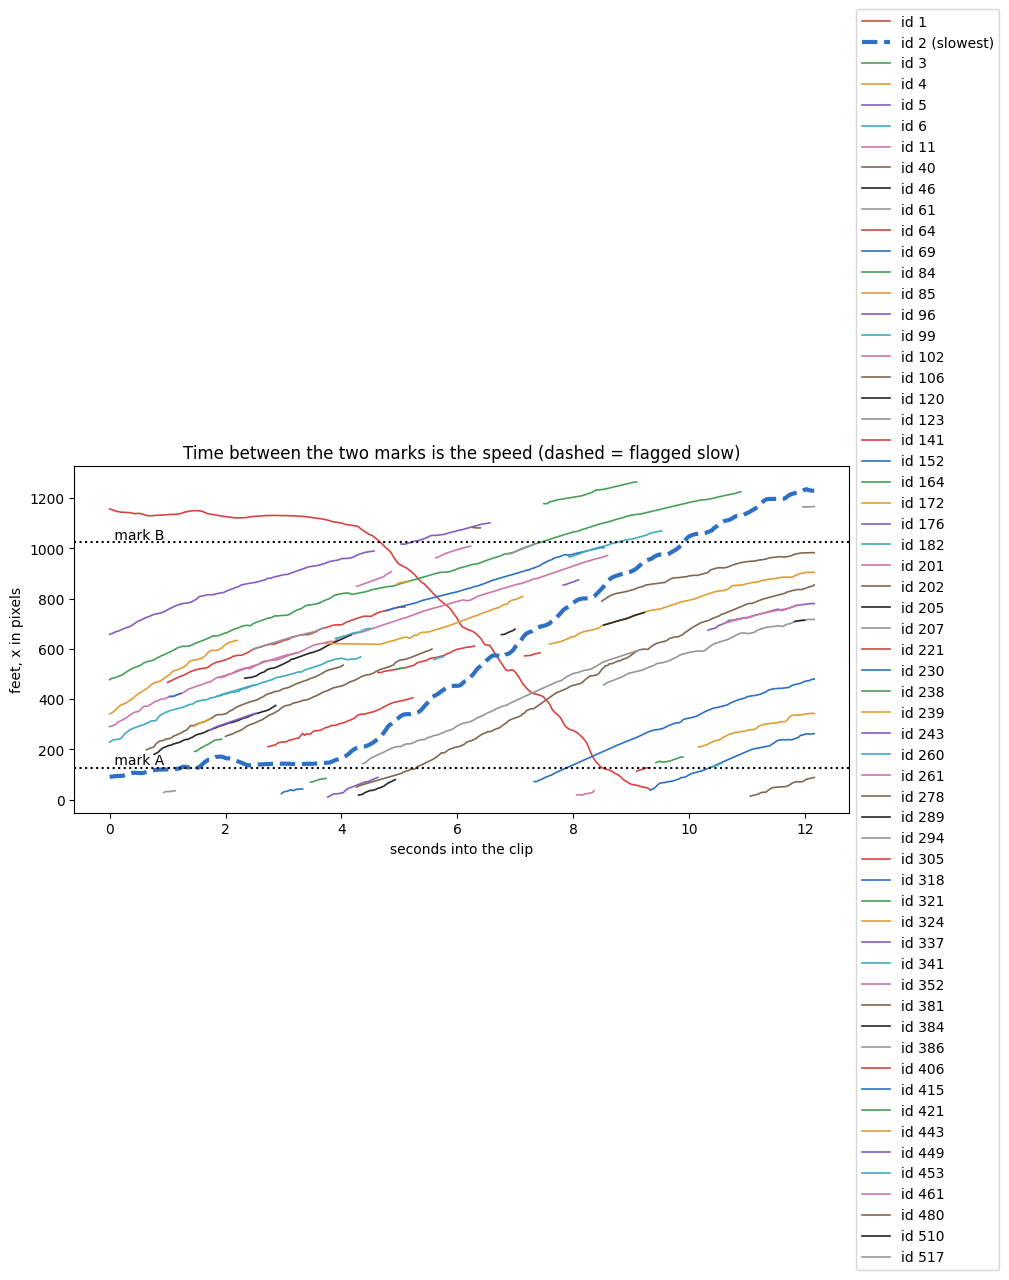

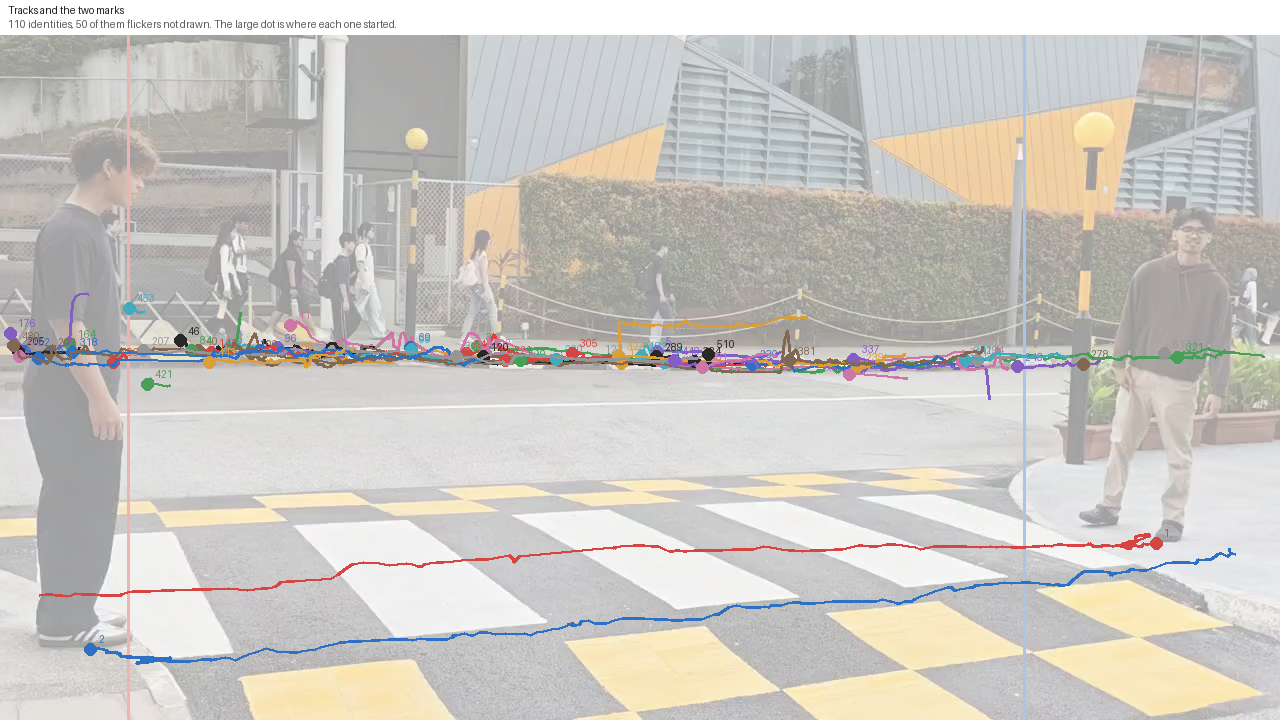

In [28]:
import matplotlib.pyplot as plt

SLOW_IDS = {row["track_id"] for row in flagged}
SLOWEST_ID = SUMMARY.get("slowest_track_id")
colours = track_colours(TRACKS)

figure, axes = plt.subplots(figsize=(10, 4.5))
for track_id, colour in colours.items():
    observations = TRACKS[track_id]
    axes.plot([o["seconds"] for o in observations],
              [o["foot"][0] for o in observations],
              color=[c / 255 for c in colour],
              linewidth=3 if track_id == SLOWEST_ID else 1.2,
              linestyle="--" if track_id in SLOW_IDS else "-",
              label="id %d%s" % (track_id, " (slowest)" if track_id == SLOWEST_ID else
                                 " (slow)" if track_id in SLOW_IDS else ""))
axes.axhline(MARK_A_X, color="black", linestyle=":")
axes.axhline(MARK_B_X, color="black", linestyle=":")
axes.text(0, MARK_A_X, " mark A", va="bottom")
axes.text(0, MARK_B_X, " mark B", va="bottom")
axes.set_xlabel("seconds into the clip")
axes.set_ylabel("feet, x in pixels")
axes.set_title("Time between the two marks is the speed (dashed = flagged slow)")
if axes.get_legend_handles_labels()[0]:
    axes.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.show()

draw_tracks(draw_marks(FIRST_FRAME, MARK_A_X, MARK_B_X), TRACKS, "Tracks and the two marks")

### Save the results

Written beside `tracks.json`, so the report can quote them without re-running anything.

In [30]:
T5_FILE = os.path.join(WORK_DIR, "t5_results.json")

with open(T5_FILE, "w", encoding="utf-8") as handle:
    json.dump({
        "clip": CLIP_PATH,
        "fps": CLIP["fps"],
        "settings": {
            "mark_a_x": MARK_A_X, "mark_b_x": MARK_B_X,
            "mark_distance_m": MARK_DISTANCE_M,
            "walkway_width_m": WALKWAY_WIDTH_M,
            "slow_threshold_ms": SLOW_THRESHOLD_MS,
            "tracker": TRACKER, "confidence": CONFIDENCE,
        },
        "summary": SUMMARY,
        "people": SPEEDS,
        "left_out": {str(k): v for k, v in LEFT_OUT.items()},
    }, handle, indent=1)

print("saved to", T5_FILE)

saved to /content/drive/MyDrive/C389/artifacts/Ca1/t5_results.json


### What to write down and justify

- **Where the marks went,** and that the tape distance was measured on the day, with the
  phone not moved since
- **Who counts as walking.** Why `STANDING_BELOW_MS` is the value it is, and what
  changed in the slowest speed with and without that rule
- **People who crossed only one mark.** How many, and why. A fragment between the marks
  loses that person, so try a larger `track_buffer` (Section 7) and say what it cost
- **The threshold** `SLOW_THRESHOLD_MS` and where the number came from
- **The slowest speed is one person.** Say how many people it rests on. Mention that
  the clearance time is only as good as the slowest person actually in the clip

Known biases, all pushing speed **down**: someone walking at an angle covers more
ground than the mark distance, and a person partly hidden near a mark has their
crossing time shifted. The frame rate is read from the video file, so check it against
the phone's setting.